# LINCS L1000 drugs on the Figure 5 meta-gene modules (MGMs)

💡 **Environment:** `clamp-analyses`

View-only report of rule `crispercas_metalv_l1000` (`scripts/archs4/crispercas/metalv/l1000_metalv.py`).
Each LINCS L1000 consensus drug signature (1,170 DrugBank drugs) is scored on each MGM's top 1% of gene loadings
(185 genes; those measured in LINCS): the mean drug z-score over these genes, standardized per drug across the
27 GSEA-significant MGMs (the PhenoPLIER set). Drugs are ranked by descending score (module induced).
Significance: 10,000 random LINCS gene sets of the same size, one-sided permutation P, BH FDR across drugs.
The gene-permutation null ignores co-expression among module genes, so FDR is lenient; rank and permutation z
are the more informative quantities.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    RANKING = Path(snakemake.input.ranking)
except NameError:
    RANKING = Path('../../../../output/03_model_biology/02_archs4/04_crispercas/03_metalv/l1000/l1000_fig5_ranking.csv')
r = pd.read_csv(RANKING)
r['MGM'] = r.metaLV.str.replace('metaLV', 'MGM')
ORDER = ['MGM91', 'MGM588', 'MGM175', 'MGM335']
PICK = {'MGM91': 'Clomifene', 'MGM588': 'Clomifene', 'MGM175': 'Cortisone acetate', 'MGM335': 'Calcitriol'}
assert set(r.MGM) == set(ORDER) and r.groupby('MGM').size().eq(1170).all()

## Mechanism-linked drug classes

Drugs expected to induce each program, defined from its biology (flagged in the tables below):
- MGM91, MGM588 (cholesterol biosynthesis / SREBP): statins, CYP51 azoles, post-squalene sterol-enzyme inhibitors and SREBP2-activating antipsychotics/antidepressants (ATC N05A, N06A).
- MGM175 (hepatocyte, complement and coagulation): glucocorticoids/corticosteroids, bile acids, fibrates, glitazones, estrogens.
- MGM335 (macrophage activation): vitamin D and retinoids (myeloid differentiation), glucocorticoids, NSAIDs, immunosuppressants.

In [2]:
def has(s, *keys):
    return s.fillna('').str.contains('|'.join(keys), case=False, regex=True)

sterol = ['statin$', 'conazole$', 'Clomifene', 'Tamoxifen', 'Amiodarone', 'Haloperidol', 'Trazodone', 'Aripiprazole', 'Trimipramine']
LINK = {
    'sterol': lambda d: has(d.drug, *sterol) & ~has(d.drug, 'Bestatin', 'Cilastatin', 'Wiskostatin', 'blebbistatin', 'Alrestatin')
                        | has(d.atc_codes, 'N05A', 'N06A'),
    'MGM175': lambda d: has(d.categories, 'Glucocorticoid', 'Corticosteroid') | has(d.drug, 'cholic', 'Ursodeoxycholic', 'fibrate$', 'Gemfibrozil', 'glitazone', 'PREGN-4-ENE')
                        | has(d.atc_codes, 'G03C'),
    'MGM335': lambda d: has(d.drug, 'Calcitriol', 'DN-101', 'Vitamin A', 'Tretinoin') | has(d.categories, 'Glucocorticoid', 'Anti-Inflammatory Agents, Non-Steroidal')
                        | has(d.atc_codes, 'L04'),
}
r['linked'] = False
for m in ORDER:
    i = r.MGM == m
    r.loc[i, 'linked'] = LINK['sterol' if m in ('MGM91', 'MGM588') else m](r[i]).values

## Selected drug per MGM (Figure 5)

In [3]:
picks = pd.concat([r[(r.MGM == m) & (r.drug == d)] for m, d in PICK.items()])
summary = r.groupby('MGM').agg(n_genes=('n_genes', 'first'), n_fdr_0_05=('fdr', lambda q: (q < 0.05).sum()),
                               linked_top10=('linked', lambda s: s.iloc[:10].sum()),
                               linked_top1pct=('linked', lambda s: s.iloc[:12].sum()))
display(picks.set_index('MGM')[['drug', 'rank', 'score', 'perm_z', 'perm_p', 'fdr']].join(summary).loc[ORDER])

,drug,rank,score,perm_z,perm_p,fdr,n_genes,n_fdr_0_05,linked_top10,linked_top1pct
MGM,,,,,,,,,,
MGM91,Clomifene,4,3.640081,18.019890,0.0001,0.001017,81,167,8,8
MGM588,Clomifene,4,2.980225,18.152338,0.0001,0.001045,90,164,8,8
MGM175,Cortisone acetate,8,2.929961,3.407734,0.0002,0.001983,48,295,2,2
MGM335,Calcitriol,14,2.376301,3.721970,0.0005,0.006290,41,210,0,1


## Top 25 drugs per MGM

In [4]:
cols = ['rank', 'drug', 'drugbank_id', 'score', 'mean_z', 'perm_z', 'fdr', 'linked']
for m in ORDER:
    print(m)
    display(r[r.MGM == m].head(25)[cols].style.format({'score': '{:.2f}', 'mean_z': '{:.2f}', 'perm_z': '{:.1f}', 'fdr': '{:.1e}'})
            .apply(lambda row: ['font-weight: bold' if row.drug == PICK[m] else '' for _ in row], axis=1).hide(axis='index'))

MGM91


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Alimemazine,DB01246,3.72,2.70,17.4,1.0e-03,False
2,Trimipramine,DB00726,3.65,2.17,14.9,1.0e-03,True
3,Maprotiline,DB00934,3.64,3.24,16.9,1.0e-03,True
4,Clomifene,DB00882,3.64,4.13,18.0,1.0e-03,True
5,Amoxapine,DB00543,3.63,1.74,14.9,1.0e-03,True
6,N-[2-(4-BROMOCINNAMYLAMINO)ETHYL]-5-ISOQUINOLINE SULFONAMIDE,DB07995,3.62,3.39,20.5,1.0e-03,False
7,Fluphenazine,DB00623,3.62,3.59,19.8,1.0e-03,True
8,Promazine,DB00420,3.61,1.97,13.6,1.0e-03,True
9,Thiothixene,DB01623,3.61,4.11,19.7,1.0e-03,True
10,Sertraline,DB01104,3.60,3.19,18.3,1.0e-03,True


MGM588


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Trimipramine,DB00726,2.99,1.80,15.5,1.0e-03,True
2,Thiothixene,DB01623,2.99,3.47,20.1,1.0e-03,True
3,Ketoconazole,DB01026,2.98,2.00,20.2,1.0e-03,True
4,Clomifene,DB00882,2.98,3.49,18.2,1.0e-03,True
5,Sertraline,DB01104,2.98,2.69,18.5,1.0e-03,True
6,"(1S,4S)-4-(3,4-dichlorophenyl)-N-methyl-1,2,3,4-tetrahydronaphthalen-1-amine",DB08567,2.98,2.69,18.5,1.0e-03,False
7,(S)-Wiskostatin,DB01731,2.98,2.39,19.0,1.0e-03,False
8,Amoxapine,DB00543,2.98,1.45,15.4,1.0e-03,True
9,Maprotiline,DB00934,2.97,2.68,17.5,1.0e-03,True
10,Fluphenazine,DB00623,2.94,2.96,20.2,1.0e-03,True


MGM175


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Acetylcholine,DB03128,3.74,1.23,6.6,1.3e-03,False
2,Temozolomide,DB00853,3.58,0.84,4.5,1.3e-03,False
3,Pralidoxime,DB00733,3.50,0.69,5.2,1.3e-03,False
4,Hyoscyamine,DB00424,3.20,0.55,3.8,1.3e-03,False
5,Atropine,DB00572,3.20,0.55,3.8,1.3e-03,False
6,Mianserin,DB06148,3.17,0.62,3.9,1.3e-03,False
7,Progesterone,DB00396,3.04,0.89,5.5,1.3e-03,False
8,Cortisone acetate,DB01380,2.93,0.44,3.4,2.0e-03,True
9,"(11-BETA)-11,21-DIHYDROXY-PREGN-4-ENE-3,20-DIONE",DB04652,2.87,0.61,4.4,1.3e-03,True
10,Ampicillin,DB00415,2.82,0.75,5.6,1.3e-03,False


MGM335


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,"2-tert-butylbenzene-1,4-diol",DB07726,3.43,0.88,3.2,6.3e-03,False
2,"(5E,14E)-11-oxoprosta-5,9,12,14-tetraen-1-oic acid",DB08435,3.17,2.38,4.1,4.4e-03,False
3,Ethacrynic acid,DB00903,2.99,0.88,3.6,2.5e-03,False
4,Doxylamine,DB00366,2.98,0.39,3.3,5.6e-03,False
5,"2',4,4'-Trihydroxychalcone",DB03285,2.86,1.34,5.0,4.4e-03,False
6,Cerulenin,DB01034,2.77,1.97,3.3,8.4e-03,False
7,Bithionol,DB04813,2.67,1.23,3.4,7.0e-03,False
8,Modafinil,DB00745,2.55,0.57,3.6,2.5e-03,False
9,Pancuronium,DB01337,2.54,0.32,2.8,2.0e-02,False
10,"METHYL N-({(2S,3S)-3-[(PROPYLAMINO)CARBONYL]OXIRAN-2-YL}CARBONYL)-L-ISOLEUCYL-L-PROLINATE",DB07223,2.53,1.33,5.2,2.5e-03,False


## Score by rank (mechanism-linked drugs in colour, Figure 5 drug labelled)

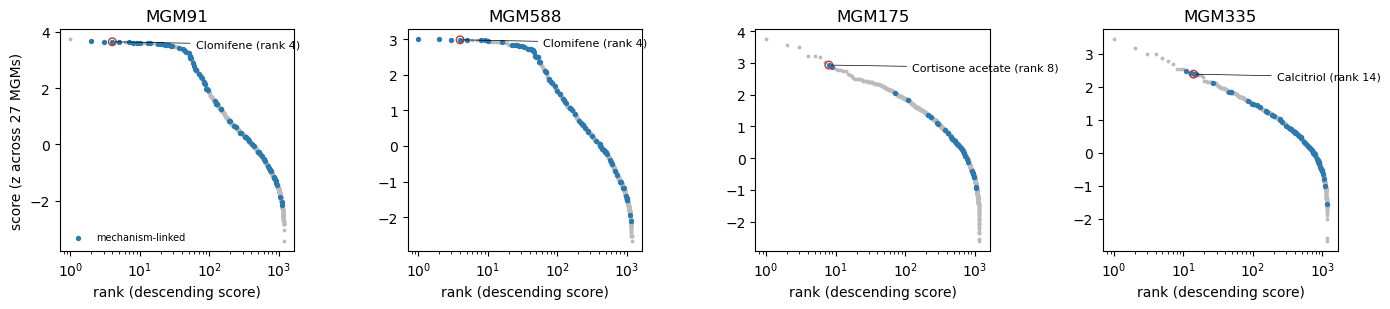

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=False)
for ax, m in zip(axes, ORDER):
    d = r[r.MGM == m]
    ax.scatter(d['rank'], d.score, s=3, c='#BBBBBB')
    ax.scatter(d[d.linked]['rank'], d[d.linked].score, s=8, c='#2A7AB0', label='mechanism-linked')
    p = d[d.drug == PICK[m]].iloc[0]
    ax.scatter(p['rank'], p.score, s=30, facecolors='none', edgecolors='#C0392B')
    ax.annotate(f"{p.drug} (rank {p['rank']})", (p['rank'], p.score), xytext=(60, -4), textcoords='offset points', fontsize=8,
                arrowprops=dict(arrowstyle='-', lw=0.5))
    ax.set(title=m, xlabel='rank (descending score)', xscale='log')
axes[0].set_ylabel('score (z across 27 MGMs)')
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()